# Bonds in Quant Finance — Live Demo

This notebook follows the talk step by step. Run each cell top to bottom (**Runtime → Run all** works too).

Market inputs try to load live from FRED. If that fails, the notebook falls back to the levels quoted in the talk

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
NAVY, ORANGE, GREEN, RED, GREY = "#1f4e79", "#e07b00", "#2e7d32", "#c62828", "#888888"
np.random.seed(42)

def fred_latest(series_id, fallback):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    try:
        df = pd.read_csv(url, na_values=".")
        s = pd.to_numeric(df.iloc[:, 1], errors="coerce").dropna()
        return float(s.iloc[-1]), str(df.iloc[s.index[-1], 0]), "FRED live"
    except Exception:
        return float(fallback), "2026-10-09/12", "fallback (talk values)"

market_inputs = {
    "UST 5Y (%)":        ("DGS5",          5.02),
    "UST 10Y (%)":       ("DGS10",         5.24),
    "SOFR (%)":          ("SOFR",          3.90),
    "AAA spread (%)":    ("BAMLC0A1CAAA",  0.38),
    "AA spread (%)":     ("BAMLC0A2CAA",   0.58),
    "A spread (%)":      ("BAMLC0A3CA",    0.70),
    "BBB spread (%)":    ("BAMLC0A4CBBB",  1.02),
    "BB spread (%)":     ("BAMLH0A1HYBB",  1.88),
}
rows = []
for name, (sid, fb) in market_inputs.items():
    val, date, src = fred_latest(sid, fb)
    rows.append((name, sid, val, date, src))
mkt = pd.DataFrame(rows, columns=["Input", "FRED id", "Value", "As of", "Source"]).set_index("Input")

UST5, UST10, SOFR = mkt.loc["UST 5Y (%)", "Value"]/100, mkt.loc["UST 10Y (%)", "Value"]/100, mkt.loc["SOFR (%)", "Value"]/100
SPREADS = {r: mkt.loc[f"{r} spread (%)", "Value"]/100 for r in ["AAA", "AA", "A", "BBB", "BB"]}
mkt

,FRED id,Value,As of,Source
Input,,,,
UST 5Y (%),DGS5,4.82,2026-10-23,FRED live
UST 10Y (%),DGS10,5.00,2026-10-23,FRED live
SOFR (%),SOFR,3.92,2026-10-23,FRED live
AAA spread (%),BAMLC0A1CAAA,0.44,2026-10-23,FRED live
AA spread (%),BAMLC0A2CAA,0.67,2026-10-23,FRED live
A spread (%),BAMLC0A3CA,0.76,2026-10-23,FRED live
BBB spread (%),BAMLC0A4CBBB,1.13,2026-10-23,FRED live
BB spread (%),BAMLH0A1HYBB,2.06,2026-10-23,FRED live


## Part 1 — What a bond is: the price–yield seesaw
A bond's price is the present value of its coupons plus face value, discounted at the market yield:

$$P = \sum_{t=1}^{n} \frac{C}{(1+y)^t} + \frac{F}{(1+y)^n}$$

US bonds pay coupons twice a year, so we use half the coupon and half the yield each period.

5-year 5% bond, $1,000 face, yield 4%:  price = $1,044.91
5-year 5% bond, $1,000 face, yield 5%:  price = $1,000.00
5-year 5% bond, $1,000 face, yield 6%:  price = $957.35


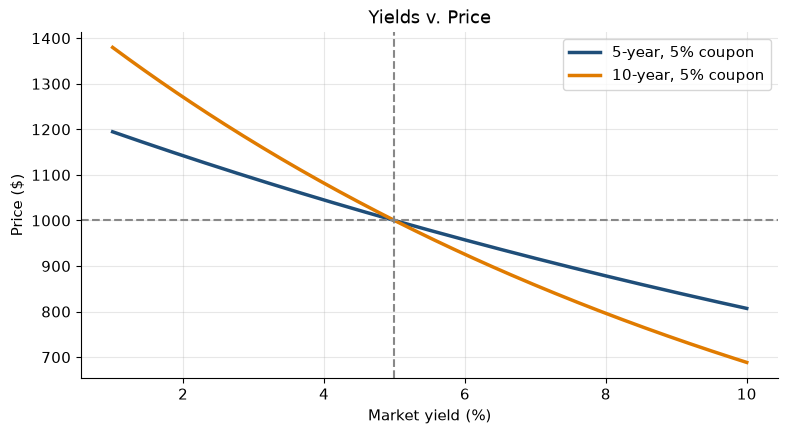

In [5]:
def bond_price(face, coupon_rate, years, ytm, freq=2):
    n = int(round(years * freq))
    c = face * coupon_rate / freq
    t = np.arange(1, n + 1)
    ytm = np.asarray(ytm, dtype=float)
    disc = (1 + ytm[..., None] / freq) ** (-t)
    return (c * disc).sum(-1) + face * disc[..., -1]

for y in [0.04, 0.05, 0.06]:
    print(f"5-year 5% bond, $1,000 face, yield {y:.0%}:  price = ${bond_price(1000, 0.05, 5, y):,.2f}")

yields = np.linspace(0.01, 0.10, 200)
plt.plot(yields*100, bond_price(1000, 0.05, 5, yields), color=NAVY, lw=2.5, label="5-year, 5% coupon")
plt.plot(yields*100, bond_price(1000, 0.05, 10, yields), color=ORANGE, lw=2.5, label="10-year, 5% coupon")
plt.axvline(5, color=GREY, ls="--"); plt.axhline(1000, color=GREY, ls="--")
plt.xlabel("Market yield (%)"); plt.ylabel("Price ($)")
plt.title("Yields v. Price")
plt.legend(); plt.show()